# Case 1 · Notebook 1: Data Exploration

This notebook does what any data scientist would do first: load the raw files, look at them,
and figure out what problems need solving before any analysis can happen.

It has four parts:

**Part 1: Raw data (just `pd.read_csv`).**  
No helper functions. We load the five source files directly and see what we're actually dealing with.
Column names, dtypes, obvious problems, the fraud label format.
This is the messy reality a real data scientist encounters.

**Part 2: What we need to build.**  
Every problem found in Part 1 becomes a concrete task: `load.py` handles the merge and label
parsing; `clean.py` handles the encoding and feature derivation. We show what the data looks
like after running both.

**Part 3: The actual exploration.**  
With clean, merged data in hand, we answer the four questions that will shape every modelling
decision that follows:
1. How rare is fraud, really?
2. What does a fraudulent transaction look like?
3. When and where does fraud happen?
4. Is the current rule at least pointing in the right direction?

**Part 4: From findings to features.**  
We know what signals are predictive. Now we formalise that into a feature matrix
that sklearn can work with, and introduce `build_features.py`.

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# warning: might need to change path to fit your data location
RAW_DIR = Path("../data/raw")

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

---
## Part 1: Raw data

We have five source files. Let's load each one directly and see what's there.

### 1.1 Transactions

In [2]:
txn_raw = pd.read_csv(RAW_DIR / "transactions_data.csv")
print(f"Shape: {txn_raw.shape}")
print(f"Columns: {list(txn_raw.columns)}")
txn_raw.head(3)

Shape: (13305915, 12)
Columns: ['id', 'date', 'client_id', 'card_id', 'amount', 'use_chip', 'merchant_id', 'merchant_city', 'merchant_state', 'zip', 'mcc', 'errors']


,id,date,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors
0,7475327,2010-01-01 00:01:00,1556,2972,$-77.00,Swipe Transaction,59935,Beulah,ND,58523.0,5499,NaN
1,7475328,2010-01-01 00:02:00,561,4575,$14.57,Swipe Transaction,67570,Bettendorf,IA,52722.0,5311,NaN
2,7475329,2010-01-01 00:02:00,1129,102,$80.00,Swipe Transaction,27092,Vista,CA,92084.0,4829,NaN


FYI: MCC stands for Merchant Category Code. It's a 4-digit number that classifies what type of business a merchant is (e.g. 5411 = Grocery Stores, 4829 = Money Transfer). Every card-accepting merchant is assigned one by the card networks.

**Why it matters for fraud detection:**

Some merchant categories are statistically associated with higher fraud rates, for example, money transfer services, electronics stores, and online gambling tend to attract more fraud attempts than groceries or pharmacies. 
The fraud team in the case scenario has "opinions about this but no hard numbers to back them up". So building sliced metrics by MCC category is exactly how you'd give them those numbers.

In the dataset, the transactions_data.csv has a raw mcc integer column, and mcc_codes.json maps those integers to human-readable category names like "Money Transfer" or "Airlines". The pipeline joins them so the model and plots work with readable labels rather than opaque 4-digit codes.

In [3]:
# Check dtypes and missing values
print(txn_raw.dtypes)
print()
print("Missing values per column:")
print(txn_raw.isna().sum())

id                  int64
date                  str
client_id           int64
card_id             int64
amount                str
use_chip              str
merchant_id         int64
merchant_city         str
merchant_state        str
zip               float64
mcc                 int64
errors                str
dtype: object

Missing values per column:
id                       0
date                     0
client_id                0
card_id                  0
amount                   0
use_chip                 0
merchant_id              0
merchant_city            0
merchant_state     1563700
zip                1652706
mcc                      0
errors            13094522
dtype: int64


In [4]:
# Look at the 'amount' column more carefully
print("Sample amount values:")
print(txn_raw["amount"].head(10).tolist())
print(f"\nDtype: {txn_raw['amount'].dtype}")
print(f"Can we compute the mean directly? Let's try:")
try:
    print(txn_raw["amount"].mean())
except Exception as e:
    print(f"  Error: {e}")

Sample amount values:
['$-77.00', '$14.57', '$80.00', '$200.00', '$46.41', '$4.81', '$77.00', '$26.46', '$261.58', '$10.74']

Dtype: str
Can we compute the mean directly? Let's try:
  Error: Cannot perform reduction 'mean' with string dtype


**Problem 1:** `amount` is stored as a string with a leading `$` sign, so it loaded as `object` dtype.
We can't do any arithmetic on it until we strip the `$` and cast to `float`.

In [5]:
# Check the date column
print("Sample date values:")
print(txn_raw["date"].head(5).tolist())
print(f"Dtype: {txn_raw['date'].dtype}")
print(f"\nCan we extract the hour directly?")
try:
    print(txn_raw["date"].dt.hour.head(3))
except Exception as e:
    print(f"  Error: {e}")

Sample date values:
['2010-01-01 00:01:00', '2010-01-01 00:02:00', '2010-01-01 00:02:00', '2010-01-01 00:05:00', '2010-01-01 00:06:00']
Dtype: str

Can we extract the hour directly?
  Error: Can only use .dt accessor with datetimelike values


**Problem 2:** `date` is also a string and it loaded as `object`.
To extract the hour of day or day of week (useful temporal features), we need to parse it first.

In [6]:
# MCC codes — what do they look like?
print("MCC code sample values:")
print(txn_raw["mcc"].value_counts().head(10))
print(f"\nDtype: {txn_raw['mcc'].dtype}")
print(f"Unique MCC codes: {txn_raw['mcc'].nunique()}")

MCC code sample values:
mcc
5411    1592584
5499    1460875
5541    1424711
5812     999738
5912     772913
4784     674135
5300     601942
4829     589140
4121     500662
5814     499659
Name: count, dtype: int64

Dtype: int64
Unique MCC codes: 109


**Problem 3:** MCC codes are raw integers (e.g. `5411`). They're meaningless without looking them up
in `mcc_codes.json`. We need to join that mapping to get human-readable merchant categories.

In [7]:
# The 'errors' column
print("Errors column - value counts:")
print(txn_raw["errors"].value_counts(dropna=False).head(10))

Errors column - value counts:
errors
NaN                                      13094522
Insufficient Balance                       130902
Bad PIN                                     32119
Technical Glitch                            26271
Bad Card Number                              7767
Bad Expiration                               6161
Bad CVV                                      6106
Bad Zipcode                                  1126
Bad PIN,Insufficient Balance                  293
Insufficient Balance,Technical Glitch         243
Name: count, dtype: int64


### 1.2 Users

In [8]:
users_raw = pd.read_csv(RAW_DIR / "users_data.csv")
print(f"Shape: {users_raw.shape}")
print(f"Columns: {list(users_raw.columns)}")
users_raw.head(3)

Shape: (2000, 14)
Columns: ['id', 'current_age', 'retirement_age', 'birth_year', 'birth_month', 'gender', 'address', 'latitude', 'longitude', 'per_capita_income', 'yearly_income', 'total_debt', 'credit_score', 'num_credit_cards']


,id,current_age,retirement_age,birth_year,birth_month,gender,address,latitude,longitude,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards
0,825,53,66,1966,11,Female,462 Rose Lane,34.15,-117.76,$29278,$59696,$127613,787,5
1,1746,53,68,1966,12,Female,3606 Federal Boulevard,40.76,-73.74,$37891,$77254,$191349,701,5
2,1718,81,67,1938,11,Female,766 Third Drive,34.02,-117.89,$22681,$33483,$196,698,5


**Note: US credit score explained**

An American credit score is a three-digit number from 300 to 850 that shows how well you handle money. Lenders use it to decide if you will pay back loans. Higher numbers mean less risk. Three main bureaus make these reports: Equifax, Experian, and TransUnion.

Score Ranges
* 300–579: Poor
* 580–669: Fair
* 670–739: Good
* 740–799: Very Good
* 800–850: Exceptional

Key Factors
* Payment history: Paying bills on time.
* Credit usage: How much credit you use versus your limit.
* Length of history: How long your accounts stay open.
* New credit: Applying for new cards or loans often.
* Credit mix: Having different types of loans or cards.

In [9]:
# The address column — how is the home state encoded?
print("Sample address values:")
for addr in users_raw["address"].head(5):
    print(f"  '{addr}'")
print(f"\nDtype: {users_raw['address'].dtype}")

Sample address values:
  '462 Rose Lane'
  '3606 Federal Boulevard'
  '766 Third Drive'
  '3 Madison Street'
  '9620 Valley Stream Drive'

Dtype: str


**Problem 4:** The home state isn't a standalone column. Instead, it's buried inside a combined address string.
To check whether a merchant is in the cardholder's home state, we need to parse it out.

Format appears to be: `street number street name, City State Zip`.

**Why this is important**

We want to know the home adress of the user/client and compare it to the address of the merchant, because that might be an imprtant indicator of fraud (blue-eyed assumption: fraud is less likely when the client purchases something at a shop in his neighborhood)

In [10]:
# yearly_income — same dollar-string problem?
print("Sample yearly_income values:", users_raw["yearly_income"].head(5).tolist())
print("Dtype:", users_raw["yearly_income"].dtype)

Sample yearly_income values: ['$59696', '$77254', '$33483', '$249925', '$109687']
Dtype: str


### 1.3 Cards

In [11]:
cards_raw = pd.read_csv(RAW_DIR / "cards_data.csv")
print(f"Shape: {cards_raw.shape}")
print(f"Columns: {list(cards_raw.columns)}")
cards_raw.head(3)

Shape: (6146, 13)
Columns: ['id', 'client_id', 'card_brand', 'card_type', 'card_number', 'expires', 'cvv', 'has_chip', 'num_cards_issued', 'credit_limit', 'acct_open_date', 'year_pin_last_changed', 'card_on_dark_web']


,id,client_id,card_brand,card_type,card_number,expires,cvv,has_chip,num_cards_issued,credit_limit,acct_open_date,year_pin_last_changed,card_on_dark_web
0,4524,825,Visa,Debit,4344676511950444,12/2022,623,YES,2,$24295,09/2002,2008,No
1,2731,825,Visa,Debit,4956965974959986,12/2020,393,YES,2,$21968,04/2014,2014,No
2,3701,825,Visa,Debit,4582313478255491,02/2024,719,YES,2,$46414,07/2003,2004,No


the committee specifically asked about premium cardholders, which we defined as Credit card holders, so let's look at those

In [12]:
print(f"Card types: {cards_raw["card_type"].unique()}")
print(cards_raw["card_type"].value_counts())

Card types: <StringArray>
['Debit', 'Credit', 'Debit (Prepaid)']
Length: 3, dtype: str
card_type
Debit              3511
Credit             2057
Debit (Prepaid)     578
Name: count, dtype: int64


In [13]:
# Boolean-looking columns — are they actually booleans?
print("has_chip unique values:", cards_raw["has_chip"].unique())
print("card_on_dark_web unique values:", cards_raw["card_on_dark_web"].unique())
print()
print("credit_limit sample values:", cards_raw["credit_limit"].head(5).tolist())
print("credit_limit dtype:", cards_raw["credit_limit"].dtype)

has_chip unique values: <StringArray>
['YES', 'NO']
Length: 2, dtype: str
card_on_dark_web unique values: <StringArray>
['No']
Length: 1, dtype: str

credit_limit sample values: ['$24295', '$21968', '$46414', '$12400', '$28']
credit_limit dtype: str


**Problem 5:** Boolean columns (`has_chip`, `card_on_dark_web`) are stored as `"Yes"/"No"` strings,
not Python booleans. We can't filter on them directly.

**Problem 6:** `credit_limit` has the same `$` prefix problem as `amount` and `yearly_income`.

**Problem 7:** Notice that `cards_data.csv` has a column called `id` (the card id) AND a `client_id`.
And `transactions_data.csv` has its own `id` (transaction id) AND `card_id`.
When we merge these tables, we'll have multiple `id` columns that clash.

**Worth pausing on:** look again at the output two cells up.

`has_chip` has two values, `YES` and `NO`. But `card_on_dark_web` has exactly **one**:
`No`, across all 6,146 cards. The column is constant.

A constant column carries no information. No model can split on it, no coefficient can
be fitted to it, and it will rank at exactly zero in any feature importance analysis
you run later. Statistically it is invisible.

Keep that in mind when you get to explainability. A column that is invisible to every
measurement you can take is not necessarily a column that is safe.

In [14]:
# Problem 5: can't use boolean directly
cards_raw[cards_raw["card_on_dark_web"] == True]  # returns empty — string "No" ≠ bool True

# Problem 6: same dollar-string issue as amount
cards_raw["credit_limit"].mean()  # TypeError


TypeError: Cannot perform reduction 'mean' with string dtype

In [ ]:
# Demonstrate the merge column clash problem
naive_merge = txn_raw.merge(cards_raw, left_on="card_id", right_on="id", how="left")
print("Columns after naively merging transactions + cards:")
print([c for c in naive_merge.columns if "id" in c.lower()])
print()
print("Full column list:")
print(naive_merge.columns.tolist())

Columns after naively merging transactions + cards:
['id_x', 'client_id_x', 'card_id', 'merchant_id', 'id_y', 'client_id_y']

Full column list:
['id_x', 'date', 'client_id_x', 'card_id', 'amount', 'use_chip', 'merchant_id', 'merchant_city', 'merchant_state', 'zip', 'mcc', 'errors', 'id_y', 'client_id_y', 'card_brand', 'card_type', 'card_number', 'expires', 'cvv', 'has_chip', 'num_cards_issued', 'credit_limit', 'acct_open_date', 'year_pin_last_changed', 'card_on_dark_web']


Pandas generates `id_x` and `id_y` suffixes automatically, giving us ambiguous column names.
Three tables means three sets of `id` columns; this will get messy fast.

The clean solution: prefix card columns with `card_` and user columns with `user_` before merging,
so all columns stay unambiguous.

### 1.4 The fraud labels are not where you'd expect them

In [ ]:
with open(RAW_DIR / "train_fraud_labels.json") as f:
    labels_raw = json.load(f)

# What's the top-level structure?
print("Top-level keys:", list(labels_raw.keys()))
print("Type of top-level value:", type(labels_raw["target"]))
print("Number of entries:", len(labels_raw["target"]))

Top-level keys: ['target']
Type of top-level value: <class 'dict'>
Number of entries: 8914963


In [ ]:
# What do the keys and values look like?
sample_items = list(labels_raw["target"].items())[:10]
print("Sample (transaction_id → label) pairs:")
for k, v in sample_items:
    print(f"  key type={type(k).__name__}, key='{k}', value type={type(v).__name__}, value='{v}'")

Sample (transaction_id → label) pairs:
  key type=str, key='10649266', value type=str, value='No'
  key type=str, key='23410063', value type=str, value='No'
  key type=str, key='9316588', value type=str, value='No'
  key type=str, key='12478022', value type=str, value='No'
  key type=str, key='9558530', value type=str, value='No'
  key type=str, key='12532830', value type=str, value='No'
  key type=str, key='19526714', value type=str, value='No'
  key type=str, key='9906964', value type=str, value='No'
  key type=str, key='13224888', value type=str, value='No'
  key type=str, key='13749094', value type=str, value='No'


**Problem 8:** The fraud labels are in a separate JSON file, not a column in the transactions CSV.
The structure is `{"target": {"transaction_id_as_string": "Yes"/"No"}}`, that is two levels of nesting,
string keys (even though the transaction `id` column is an integer), and string values.

To join this to the transactions table:
1. Access `labels["target"]` to get the inner dict
2. Convert to a Series with integer index (so it matches `transactions.id`)
3. Map `"Yes"` to `True`, `"No"` to `False`
4. Join on transaction id

In [ ]:
# Show what happens if you forget the string key issue
labels_series = pd.Series(labels_raw["target"])  # keys are strings like '0', '1', ...
print("Label series index dtype:", labels_series.index.dtype)
print("Transaction id dtype:", txn_raw["id"].dtype)
print()
# Try a direct join without fixing the key type
test_join = txn_raw[["id"]].head(5).assign(id_str=txn_raw["id"].astype(str))
test_join["label_via_int"] = test_join["id"].map(labels_series)   # won't match
test_join["label_via_str"] = test_join["id_str"].map(labels_series)  # will match
print(test_join)

Label series index dtype: str
Transaction id dtype: int64

        id   id_str label_via_int label_via_str
0  7475327  7475327           NaN            No
1  7475328  7475328           NaN            No
2  7475329  7475329           NaN            No
3  7475331  7475331           NaN           NaN
4  7475332  7475332           NaN            No


### 1.5 MCC codes

In [ ]:
with open(RAW_DIR / "mcc_codes.json") as f:
    mcc_codes = json.load(f)

print(f"Number of MCC codes: {len(mcc_codes)}")
print("Sample entries:")
for k, v in list(mcc_codes.items())[:5]:
    print(f"  '{k}': '{v}'")
print()
print("Key type:", type(list(mcc_codes.keys())[0]))
print("Transaction mcc dtype:", txn_raw["mcc"].dtype)

Number of MCC codes: 109
Sample entries:
  '5812': 'Eating Places and Restaurants'
  '5541': 'Service Stations'
  '7996': 'Amusement Parks, Carnivals, Circuses'
  '5411': 'Grocery Stores, Supermarkets'
  '4784': 'Tolls and Bridge Fees'

Key type: <class 'str'>
Transaction mcc dtype: int64


Same type-mismatch pattern: the JSON has string keys (`"5411"`) but the transactions `mcc` column
is integer. We need to convert before the lookup will work.

Also: 107 unique MCC codes is too many to use as one-hot features, we'd get 107 dummy columns.
A better approach is to bucket the less-common codes into an `"Other"` category.

### Summary: what we found in the raw data

| Problem | Where | Fix needed |
|---|---|---|
| Dollar-sign strings | `amount`, `credit_limit`, `yearly_income` | Strip `$` and cast to `float` |
| Date is a string | `transactions.date` | Parse with `pd.to_datetime`, extract hour and day-of-week |
| Home state buried in address | `users.address` | Parse the last two words before the zip code |
| Yes/No boolean strings | `has_chip`, `card_on_dark_web` | Map to `True`/`False` |
| Column name clashes on merge | `id` appears in all three tables | Prefix card columns with `card_`, user columns with `user_` |
| Fraud labels in a separate JSON | `train_fraud_labels.json` | Navigate nested structure, fix string key types, merge on `tx_id` |
| MCC codes are raw integers | `transactions.mcc` | Join `mcc_codes.json` (handling string/int type mismatch) |
| 107 MCC categories | After MCC join | Bucket rare categories into `"Other"` |

This is exactly the kind of thing that consumes the first day of a real data project.
The next section shows where we've packaged all of this so it doesn't need to be done
again in every notebook.

---
## Part 2: The solution: `load.py` and `clean.py`

Rather than repeating all of the above in every notebook, we've packaged the fix into two modules:

**`shared/load_raw.py` → called by `src/load.py`**  
Handles everything about getting the five raw files into one merged DataFrame:
- Loads all five files
- Prefixes card columns with `card_`, user columns with `user_`
- Navigates the nested JSON label structure and joins it on transaction id
- Joins MCC code descriptions on `mcc` (as string)
- Returns a single merged DataFrame with `is_fraud` as a boolean column

**`src/clean.py`**  
Handles all of the column-level encoding:
- Strips `$` from dollar-string columns and casts to float
- Parses `date` to datetime and extracts `transaction_hour`, `transaction_dow`
- Tries to parse the home state out of the `user_address` string
- Derives `is_foreign_state` (merchant state ≠ home state), filling anything it
  could not work out with `True`
- Normalises `Yes`/`No` to `True`/`False`

Those middle two steps are worth keeping an eye on. Part 3 checks what they
actually produce, and the answer is not what this description implies.

In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

from src.load import load_case1_data
from src.clean import clean
from src.build_features import load_config

CONFIG = load_config("../config.yaml")

In [ ]:
# Load and clean a 200k-row stratified sample
# (large enough to be representative; small enough that plots render in seconds)
df_raw = load_case1_data(RAW_DIR, sample_n=200_000, random_state=CONFIG["random_state"])
df = clean(df_raw)

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print(f"Date range: {df['date'].min().date()} → {df['date'].max().date()}")
print(f"is_fraud dtype: {df['is_fraud'].dtype}  (was 'Yes'/'No' in raw JSON)")
print(f"amount dtype:   {df['amount'].dtype}  (was '$X.XX' string in raw CSV)")
print(f"Fraud cases:    {df['is_fraud'].sum():,}")
df.head(3)

FileNotFoundError: [Errno 2] No such file or directory: '..\\..\\data\\raw\\transactions_data.csv'

In [ ]:
# What columns do we have, and where did they come from?
card_cols  = [c for c in df.columns if c.startswith("card_")]
user_cols  = [c for c in df.columns if c.startswith("user_")]
txn_cols   = [c for c in df.columns
              if not c.startswith(("card_", "user_")) and c not in ("mcc_category",)]

print(f"Transaction columns ({len(txn_cols)}): {txn_cols}")
print(f"Card columns ({len(card_cols)}):        {card_cols}")
print(f"User columns ({len(user_cols)}):        {user_cols}")
print()
print("Derived columns added by clean.py:")
print("  transaction_hour  : extracted from 'date'")
print("  transaction_dow   : extracted from 'date'")
print("  is_foreign_state  : merchant_state ≠ home state (parsed from user_address)")
print("  mcc_category      : looked up from mcc_codes.json, bucketed to top 15 + Other")

Transaction columns (15): ['id', 'date', 'client_id', 'amount', 'use_chip', 'merchant_id', 'merchant_city', 'merchant_state', 'zip', 'mcc', 'errors', 'is_fraud', 'transaction_hour', 'transaction_dow', 'is_foreign_state']
Card columns (13):        ['card_id', 'card_client_id', 'card_card_brand', 'card_card_type', 'card_card_number', 'card_expires', 'card_cvv', 'card_has_chip', 'card_num_cards_issued', 'card_credit_limit', 'card_acct_open_date', 'card_year_pin_last_changed', 'card_card_on_dark_web']
User columns (14):        ['user_current_age', 'user_retirement_age', 'user_birth_year', 'user_birth_month', 'user_gender', 'user_address', 'user_latitude', 'user_longitude', 'user_per_capita_income', 'user_yearly_income', 'user_total_debt', 'user_credit_score', 'user_num_credit_cards', 'user_home_state']

Derived columns added by clean.py:
  transaction_hour  : extracted from 'date'
  transaction_dow   : extracted from 'date'
  is_foreign_state  : merchant_state ≠ home state (parsed from use

---
## Part 3: The actual exploration

Now that we have clean data, we can answer the four questions that matter.

### Question 1: How rare is fraud?

The fraud team mentioned it's 'well under 1%'. Let's put an exact number on it because this number determines which evaluation metrics are even meaningful.

In [ ]:
fraud_rate = df["is_fraud"].mean()
n_fraud = df["is_fraud"].sum()

print(f"Fraud rate:          {fraud_rate:.4%}")
print(f"Fraud transactions:  {n_fraud:,} of {len(df):,}")
print(f"Ratio of legit:fraud {(1-fraud_rate)/fraud_rate:.0f} : 1")
print()
print("Implication: a model that flags nothing at all would be 'correct'")
print(f"{1-fraud_rate:.4%} of the time. Accuracy is useless here.")

NameError: name 'df' is not defined

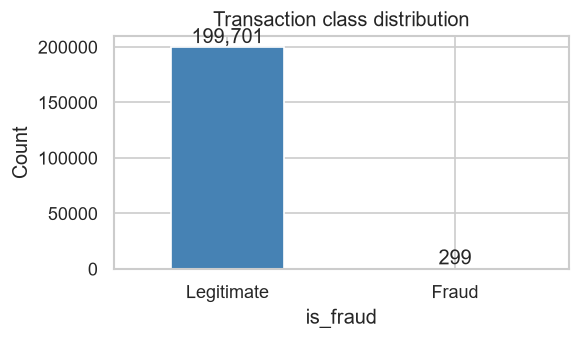

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3))
counts = df["is_fraud"].value_counts().rename({False: "Legitimate", True: "Fraud"})
counts.plot(kind="bar", ax=ax, color=["steelblue", "crimson"], edgecolor="white")
ax.set_title("Transaction class distribution")
ax.set_ylabel("Count")
ax.set_xticklabels(["Legitimate", "Fraud"], rotation=0)
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
plt.tight_layout()
plt.savefig("../outputs/eda_class_distribution.png", dpi=150)
plt.show()

### Question 2: What does a fraudulent transaction look like?

The current rule flags anything over $400. Is amount actually a strong signal?
Let's look at how the distributions compare.

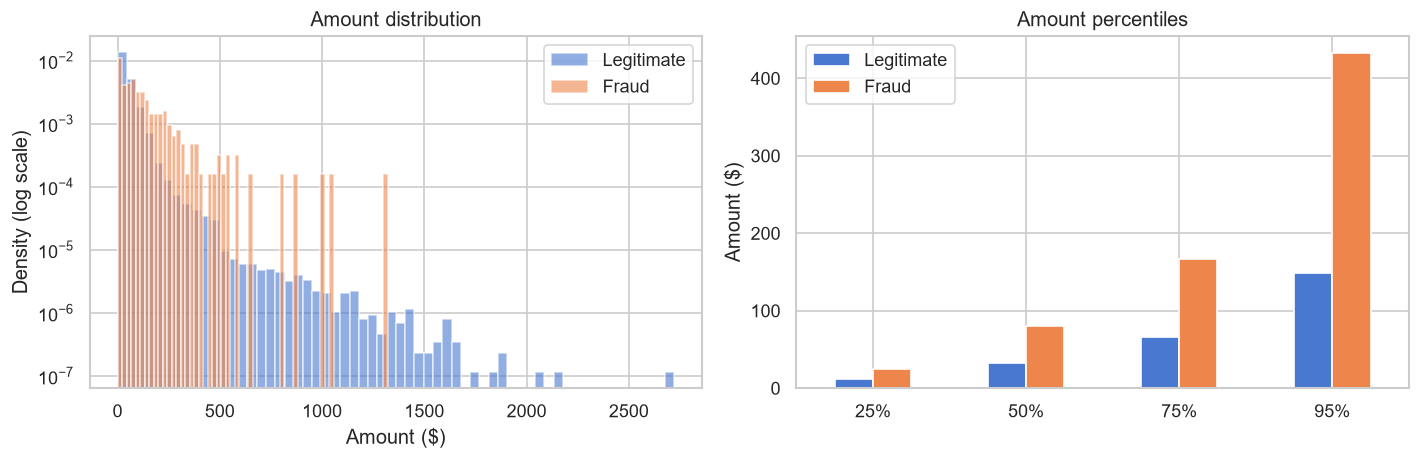

               count    mean     std   min    25%    50%     75%      max
is_fraud                                                                 
Legitimate  189628.0   50.39   72.72  0.01  11.10  31.96   66.13  2721.96
Fraud          288.0  131.46  170.79  0.01  24.24  79.59  166.02  1322.30


In [ ]:
pos = df[df["amount"] > 0].copy()  # exclude refunds / reversals

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label, group in pos.groupby("is_fraud")["amount"]:
    axes[0].hist(group, bins=60, alpha=0.6,
                 label="Fraud" if label else "Legitimate", density=True)
axes[0].set_yscale("log")
axes[0].set_xlabel("Amount ($)")
axes[0].set_ylabel("Density (log scale)")
axes[0].set_title("Amount distribution")
axes[0].legend()

stats = pos.groupby("is_fraud")["amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.95])[["25%", "50%", "75%", "95%"]]
stats.index = ["Legitimate", "Fraud"]
stats.T.plot(kind="bar", ax=axes[1])
axes[1].set_title("Amount percentiles")
axes[1].set_ylabel("Amount ($)")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.savefig("../outputs/eda_amount_distribution.png", dpi=150)
plt.show()

print(pos.groupby("is_fraud")["amount"].describe().round(2).rename(index={False: "Legitimate", True: "Fraud"}))

**What this tells us:** Fraudulent transactions tend to be larger on average, but the distributions
heavily overlap. The $400 threshold alone misses most fraud and still flags a lot of legitimate spend.
Amount is a useful feature, but not a sufficient one on its own.

### Question 3: When and where does fraud happen?

These features (`transaction_hour`, `transaction_dow`, `is_foreign_state`) only exist
because `clean.py` derived them, which is exactly what Part 2 was building up to.

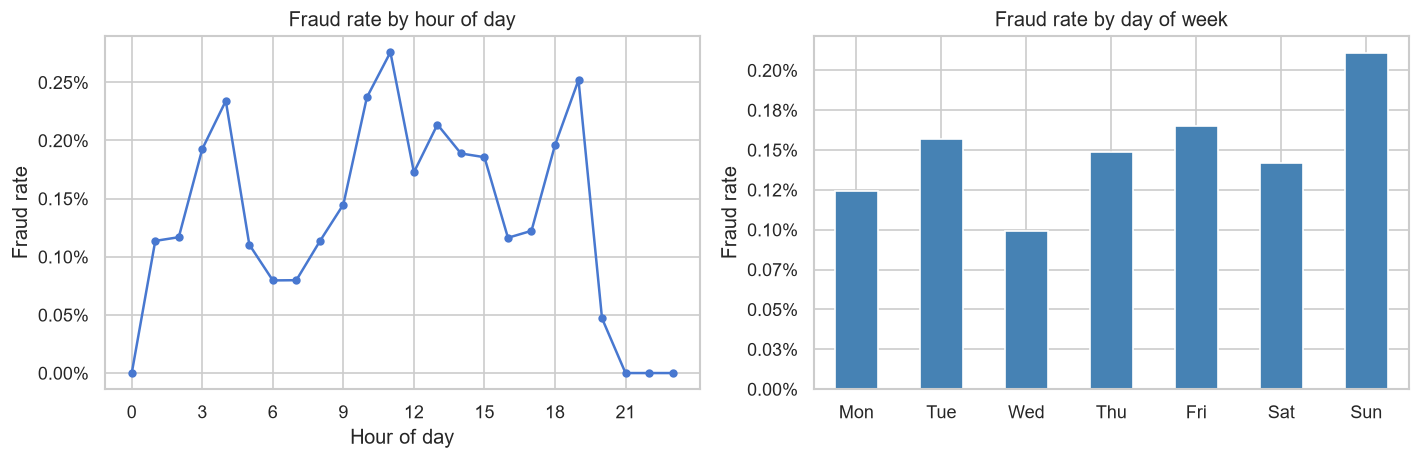

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

hourly = df.groupby("transaction_hour")["is_fraud"].mean()
hourly.plot(ax=axes[0], marker="o", markersize=4)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=2))
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Fraud rate")
axes[0].set_title("Fraud rate by hour of day")
axes[0].set_xticks(range(0, 24, 3))

dow_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow = df.groupby("transaction_dow")["is_fraud"].mean()
dow.index = dow_labels[:len(dow)]
dow.plot(kind="bar", ax=axes[1], color="steelblue", edgecolor="white")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=2))
axes[1].set_ylabel("Fraud rate")
axes[1].set_title("Fraud rate by day of week")
axes[1].set_xticklabels(dow_labels[:len(dow)], rotation=0)

plt.tight_layout()
plt.savefig("../outputs/eda_temporal_patterns.png", dpi=150)
plt.show()

### Question 4: Is the current rule pointing in the right direction?

The rule flags transactions outside the customer's home state.
To check this, we need to compare `merchant_state` against the cardholder's home state, which `clean.py` tries to parse from the `user_address` column.
Let's see how well that works.

In [ ]:
# First: check what the address column actually contains
print("Sample user_address values from the raw data:")
for addr in df["user_address"].head(8):
    print(f"  '{addr}'")
print()

# Check how many rows have a parseable home state
print("is_foreign_state coverage:")
print(df["is_foreign_state"].value_counts(dropna=False))
print(f"\nNaN rate: {df['is_foreign_state'].isna().mean():.1%}")

Sample user_address values from the raw data:
  '716 Lafayette Street'
  '801 Mill Boulevard'
  '933 Valley Lane'
  '9620 Valley Stream Drive'
  '766 Mountain View Drive'
  '9982 Summit Boulevard'
  '39126 El Camino Boulevard'
  '186 Forest Avenue'

is_foreign_state coverage:
is_foreign_state
True    200000
Name: count, dtype: int64

NaN rate: 0.0%


**What we found:** The `user_address` column contains street names only, with no city, state, or zip code.
The home state parser in `clean.py` can't extract a state from `"462 Rose Lane"`,
so `user_home_state` is NaN for every row.

Look closely at what that does to `is_foreign_state`. The comparison
`merchant_state != user_home_state` is NaN everywhere, and `clean.py` fills those NaNs with `True`.
The result is a column that is `True` for all 200,000 rows. It has no variance at all.
It is in the feature list, it will be handed to your model, and it cannot possibly
tell the model anything.

**What this means for the model:**  
The spirit of the current business rule (flag transactions away from home) can't be tested through `is_foreign_state` as it stands. That is a genuine finding, and worth
stating plainly to the committee.

It is a finding about *this column*, though, not about geography in general.
Whether this dataset gives you location information some other way is worth
checking before you write the whole idea off.

This is the kind of gap you only find by actually looking at the data, and it's exactly
why exploration comes before modelling.

### Which merchant categories have the highest fraud rates?

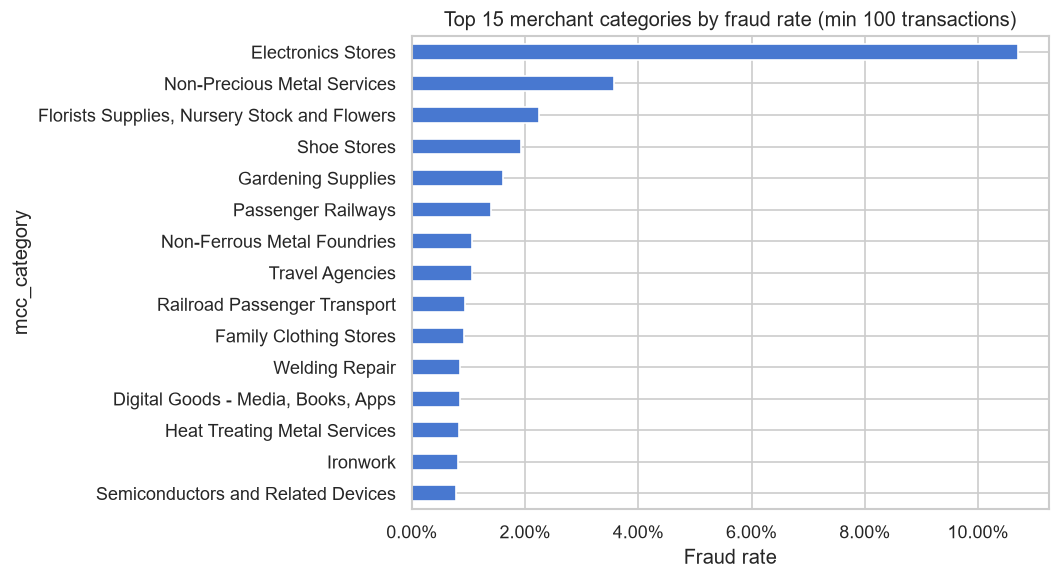

In [ ]:
mcc_stats = (
    df.groupby("mcc_category")["is_fraud"]
    .agg(fraud_rate="mean", n_transactions="count")
    .query("n_transactions >= 100")
    .sort_values("fraud_rate", ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(9, 5))
mcc_stats["fraud_rate"][::-1].plot(kind="barh", ax=ax)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=2))
ax.set_xlabel("Fraud rate")
ax.set_title("Top 15 merchant categories by fraud rate (min 100 transactions)")
plt.tight_layout()
plt.savefig("../outputs/eda_mcc_fraud_rates.png", dpi=150)
plt.show()

### Does card type matter?

The committee is particularly concerned about premium (Credit) cardholders.
Note: the dataset has no explicit tier labels: `card_type` values are `Credit`,
`Debit`, and `Debit (Prepaid)`. We'll define 'premium' as Credit card holders.

In [ ]:
card_stats = (
    df.groupby("card_card_type")["is_fraud"]
    .agg(fraud_rate="mean", n_transactions="count")
    .sort_values("fraud_rate", ascending=False)
)
card_stats["fraud_rate_pct"] = card_stats["fraud_rate"].map("{:.3%}".format)
print(card_stats[["n_transactions", "fraud_rate_pct"]])

                 n_transactions fraud_rate_pct
card_card_type                                
Debit (Prepaid)           13753         0.182%
Credit                    61786         0.162%
Debit                    124461         0.140%


---
## Summary of exploration findings

| Finding | Implication for modelling |
|---|---|
| Fraud rate ≈ 0.15% | Accuracy is useless. Use PR-AUC. |
| Fraud amounts are higher on average but heavily overlap | Amount is useful but not sufficient alone |
| Temporal patterns visible by hour and day | `transaction_hour` and `transaction_dow` are worth including |
| `user_address` contains street name only, no state | `is_foreign_state` ends up constant `True`: zero variance, contributes nothing, and can't validate the current rule's core assumption |
| `card_on_dark_web` is constant `No` across all 6,146 cards | Zero variance. Will rank at zero in any importance analysis, which is not the same as being harmless |
| Merchant categories differ significantly | MCC category belongs in the model |
| Card types differ slightly | Include `card_type` and track premium FPR separately |

Two of the columns in the feature list carry no information at all. Both will be
handed to your model anyway. Whether that matters, and what you would say to the
committee about it, is worth deciding before you present.

These findings directly inform which columns we turn into model features, which is what Part 4 covers.

---
## Part 4: From findings to features (`build_features.py`)

We've identified what the data contains and which signals are predictive.
The next step is turning that knowledge into a **feature matrix**: a numeric table
where each row is one transaction and each column is an input to the model.

This is more than just selecting columns. We need to:
- Keep only the columns the model will actually use (drop IDs, dates, raw strings)
- One-hot encode categorical columns (`mcc_category`, `use_chip`, `card_type`, `card_brand`)
- Keep binary flags as 0/1 integers
- Separate the target column (`is_fraud`) from the features

Rather than doing this inline in every notebook, it's packaged in `src/build_features.py`.
The feature list itself lives in `config.yaml`, which means changing which features to
include only requires editing the config, not the code.

In [ ]:
import yaml

# Show the feature list from config.yaml — this drives everything in build_features.py
with open("../config.yaml") as f:
    cfg = yaml.safe_load(f)

print("Numeric features (used as-is):")
print(" ", cfg["features"]["numeric"])
print()
print("Categorical features (will be one-hot encoded):")
print(" ", cfg["features"]["categorical"])
print()
print("Binary features (mapped to 0/1):")
print(" ", cfg["features"]["binary"])
print()
print("Note: 'card_on_dark_web' is in the binary list on purpose, even though")
print("we saw in Part 1 that it is constant and cannot help any model.")
print("Why you might deliberately keep a column that contributes nothing")
print("is a question worth sitting with before you get to explainability.")

Numeric features (used as-is):
  ['amount', 'transaction_hour', 'transaction_dow', 'credit_score', 'yearly_income', 'current_age', 'credit_limit']

Categorical features (will be one-hot encoded):
  ['use_chip', 'mcc_category', 'card_type', 'card_brand']

Binary features (mapped to 0/1):
  ['is_foreign_state', 'has_chip', 'card_on_dark_web']

Note: 'card_on_dark_web' is in the binary list on purpose, even though
we saw in Part 1 that it is constant and cannot help any model.
Why you might deliberately keep a column that contributes nothing
is a question worth sitting with before you get to explainability.


In [ ]:
from src.build_features import build_features

X, y = build_features(df, CONFIG)

print(f"Feature matrix shape: {X.shape}  ({X.shape[0]:,} transactions × {X.shape[1]} features)")
print(f"Target shape:         {y.shape}  (True = fraud, False = legitimate)")
print(f"Fraud in target:      {y.sum():,} ({y.mean():.3%})")
print()
print("Feature columns:")
print(list(X.columns))

Feature matrix shape: (200000, 23)  (200,000 transactions × 23 features)
Target shape:         (200000,)  (True = fraud, False = legitimate)
Fraud in target:      299 (0.149%)

Feature columns:
['amount', 'transaction_hour', 'transaction_dow', 'is_foreign_state', 'card_has_chip', 'card_card_on_dark_web', 'use_chip_Online Transaction', 'use_chip_Swipe Transaction', 'mcc_category_Department Stores', 'mcc_category_Discount Stores', 'mcc_category_Drinking Places (Alcoholic Beverages)', 'mcc_category_Drug Stores and Pharmacies', 'mcc_category_Eating Places and Restaurants', 'mcc_category_Fast Food Restaurants', 'mcc_category_Grocery Stores, Supermarkets', 'mcc_category_Miscellaneous Food Stores', 'mcc_category_Money Transfer', 'mcc_category_Other', 'mcc_category_Service Stations', 'mcc_category_Taxicabs and Limousines', 'mcc_category_Tolls and Bridge Fees', 'mcc_category_Utilities - Electric, Gas, Water, Sanitary', 'mcc_category_Wholesale Clubs']


In [ ]:
# The categorical columns were one-hot encoded — let's see what that produces
numeric_cols     = cfg["features"]["numeric"]
binary_cols      = [c for c in X.columns if any(c.startswith(b.replace("card_", "card_card_"))
                    or c == b for b in cfg["features"]["binary"])]
onehot_cols      = [c for c in X.columns if c not in numeric_cols and c not in binary_cols]

print(f"Numeric  ({len(numeric_cols)}): {numeric_cols}")
print()
print(f"One-hot  ({len(onehot_cols)}): {onehot_cols}")
print()
print(f"Binary   ({len(binary_cols)}): {binary_cols}")
print()
print("One-hot encoding: each category becomes its own 0/1 column.")
print(f"'mcc_category' had 109 raw codes — bucketed to top 15 + 'Other' = {sum(1 for c in onehot_cols if 'mcc' in c)} columns.")

Numeric  (7): ['amount', 'transaction_hour', 'transaction_dow', 'credit_score', 'yearly_income', 'current_age', 'credit_limit']

One-hot  (18): ['card_has_chip', 'use_chip_Online Transaction', 'use_chip_Swipe Transaction', 'mcc_category_Department Stores', 'mcc_category_Discount Stores', 'mcc_category_Drinking Places (Alcoholic Beverages)', 'mcc_category_Drug Stores and Pharmacies', 'mcc_category_Eating Places and Restaurants', 'mcc_category_Fast Food Restaurants', 'mcc_category_Grocery Stores, Supermarkets', 'mcc_category_Miscellaneous Food Stores', 'mcc_category_Money Transfer', 'mcc_category_Other', 'mcc_category_Service Stations', 'mcc_category_Taxicabs and Limousines', 'mcc_category_Tolls and Bridge Fees', 'mcc_category_Utilities - Electric, Gas, Water, Sanitary', 'mcc_category_Wholesale Clubs']

Binary   (2): ['is_foreign_state', 'card_card_on_dark_web']

One-hot encoding: each category becomes its own 0/1 column.
'mcc_category' had 109 raw codes — bucketed to top 15 + 'Other' = 

### Using and extending `build_features()`

One call gives you everything downstream needs:

```python
X, y = build_features(df, CONFIG)
```

`X` is the feature matrix the model sees, `y` is the fraud label.

**To change which features are used:** edit the lists in `config.yaml`. The function reads
them at call time, so no notebook code changes.

**To add a feature of your own:** two steps, and the second one is easy to forget.

1. create the column on `df`
2. add its name to the matching list in `config.yaml`

A column that exists on `df` but is not named in `config.yaml` is silently dropped. No
error, no warning, it simply will not appear in `X`.

In [ ]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))

from src.load import load_case1_data
from src.clean import clean
from src.build_features import load_config
from src.train import apply_baseline_rule
import numpy as np

CONFIG = load_config("../config.yaml")

df_raw = load_case1_data(
    "../data/raw",
    sample_n=None,
    random_state=CONFIG["random_state"],
)
df = clean(df_raw)

y_true = df["is_fraud"].astype(bool)
pred_current = apply_baseline_rule(df, CONFIG).astype(bool)

outcome = np.select(
    [
        ~y_true & ~pred_current,
        ~y_true & pred_current,
        y_true & ~pred_current,
        y_true & pred_current,
    ],
    ["TN", "FP", "FN", "TP"],
)

df["outcome"] = outcome

confusion = pd.crosstab(y_true, pred_current).reindex(
    index=[False, True],
    columns=[False, True],
    fill_value=0,
)
print("Confusion matrix (rows: actual False/True; columns: predicted False/True):")
print(confusion)

print("\nTransaction counts and amount totals by outcome:")
print(
    df.groupby("outcome")["amount"]
      .agg(transactions="size", amount_sum="sum", average_amount="mean")
      .reindex(["TN", "FP", "FN", "TP"])
      .round(2)
)

missed_fraud = y_true & ~pred_current
print(
    "\nMissed fraud positive transaction amounts: $"
    f"{df.loc[missed_fraud & (df['amount'] > 0), 'amount'].sum():,.2f}"
)


TypeError: Choicelist and default value do not have a common dtype: The DType <class 'numpy.dtypes._PyLongDType'> could not be promoted by <class 'numpy.dtypes.StrDType'>. This means that no common DType exists for the given inputs. For example they cannot be stored in a single array unless the dtype is `object`. The full list of DTypes is: (<class 'numpy.dtypes.StrDType'>, <class 'numpy.dtypes.StrDType'>, <class 'numpy.dtypes.StrDType'>, <class 'numpy.dtypes.StrDType'>, <class 'numpy.dtypes._PyLongDType'>)

### Full-data feature correlations

This uses every labelled transaction and the model-ready features from `build_features` (categorical features are one-hot encoded). Pearson correlation describes association, not causation; fraud is rare, so correlations with `is_fraud` may be small. The strongest absolute correlations with fraud are also listed below the heatmap.

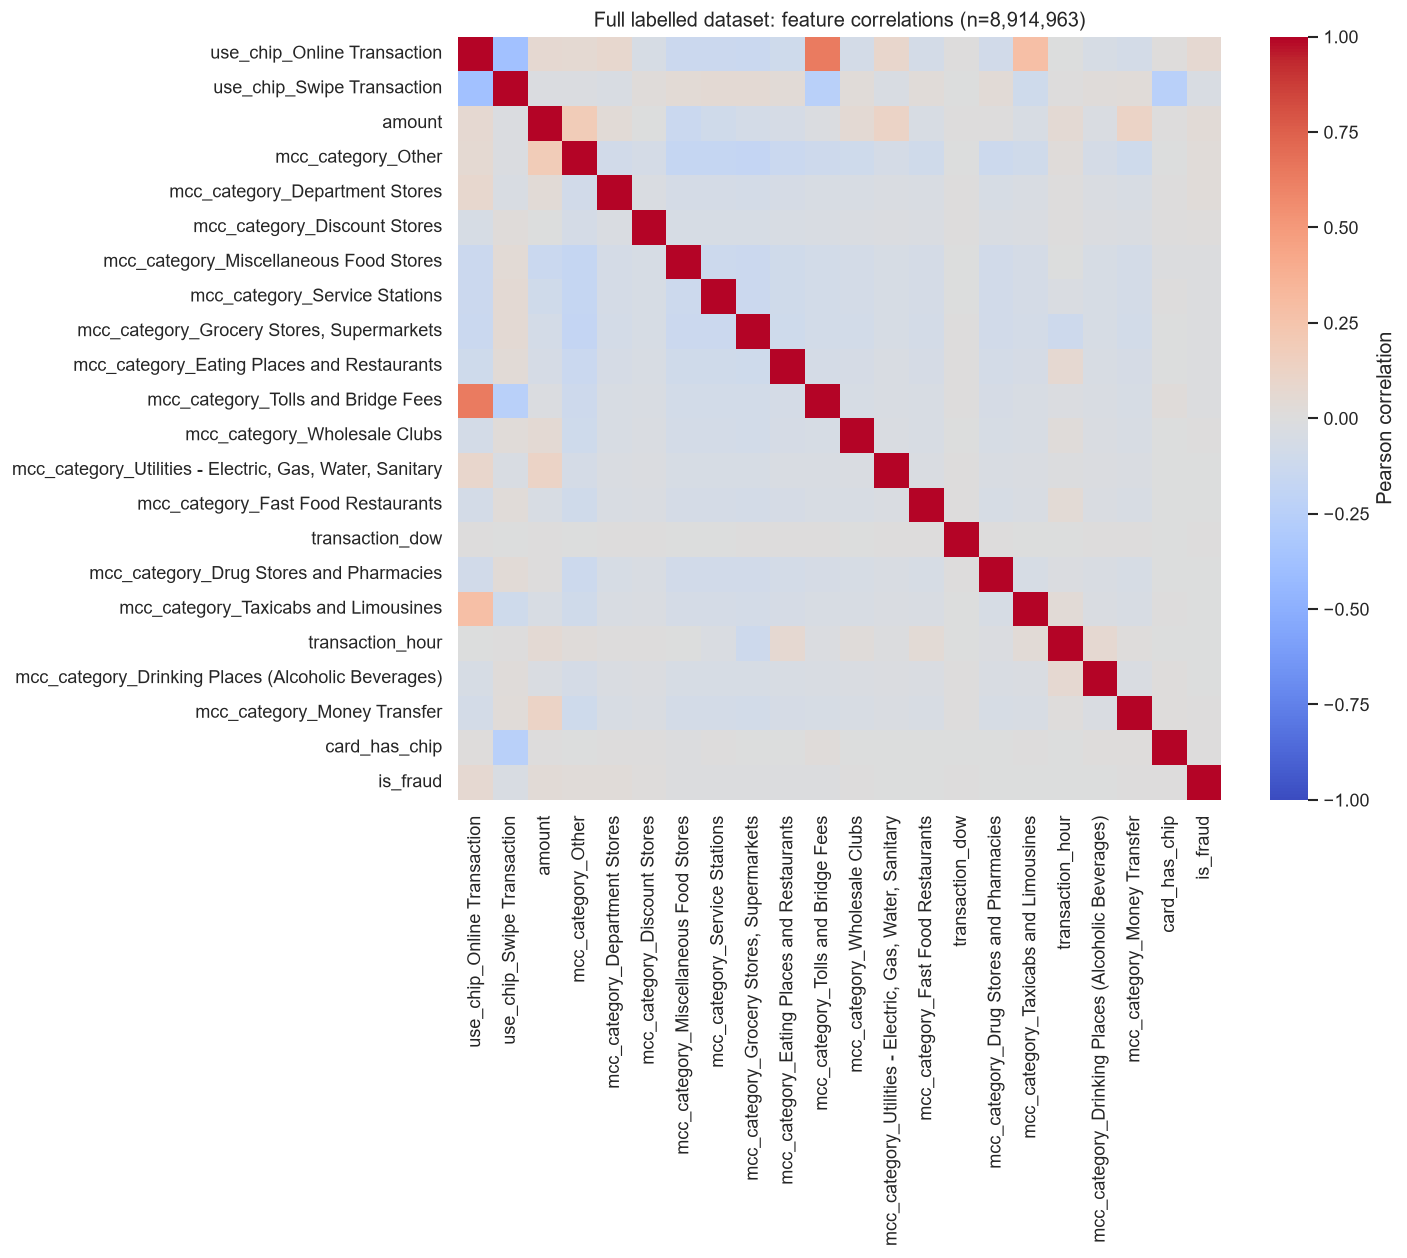

,correlation with is_fraud
use_chip_Online Transaction,0.065160
use_chip_Swipe Transaction,-0.032572
amount,0.031940
mcc_category_Other,0.029697
mcc_category_Department Stores,0.027755
mcc_category_Discount Stores,0.013132
mcc_category_Miscellaneous Food Stores,-0.012380
mcc_category_Service Stations,-0.011829
"mcc_category_Grocery Stores, Supermarkets",-0.010468
mcc_category_Eating Places and Restaurants,-0.009698


In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd()
if not (project_root / "config.yaml").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.build_features import build_features, load_config
from src.clean import clean
from src.load import load_case1_data

config = load_config(project_root / "config.yaml")
df_full = clean(load_case1_data(project_root / "data" / "raw", sample_n=None))
X_corr, y_corr = build_features(df_full, config)
X_corr["is_fraud"] = y_corr.astype("int8")
del df_full, y_corr

# Constant columns have undefined correlations and add no information.
X_corr = X_corr.loc[:, X_corr.nunique(dropna=False) > 1]
corr_matrix = X_corr.corr(method="pearson")
fraud_corr = corr_matrix["is_fraud"].drop("is_fraud").sort_values(
    key=lambda values: values.abs(), ascending=False
)
feature_order = fraud_corr.index.tolist() + ["is_fraud"]

fig_size = max(12, 0.55 * len(feature_order))
fig, ax = plt.subplots(figsize=(fig_size, fig_size * 0.85))
sns.heatmap(
    corr_matrix.loc[feature_order, feature_order],
    cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
    cbar_kws={"label": "Pearson correlation"}, ax=ax,
)
ax.set_title(f"Full labelled dataset: feature correlations (n={len(X_corr):,})")
ax.tick_params(axis="x", labelrotation=90)
ax.tick_params(axis="y", labelrotation=0)
fig.tight_layout()
plt.show()


In [ ]:
# Use every labeled transaction for calendar-time trends, not the 200k-row model sample.
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

raw_dir = next(
    (
        path for path in (
            Path("../data/raw"),
            Path("data/raw"),
            Path("case-BDAIM-FraudDetection1/data/raw"),
        )
        if path.is_dir()
    ),
    None,
)
if raw_dir is None:
    raise FileNotFoundError("Could not find data/raw relative to the notebook or project root.")

if "labels_raw" in globals():
    fraud_labels = labels_raw["target"]
else:
    with open(raw_dir / "train_fraud_labels.json", encoding="utf-8") as labels_file:
        fraud_labels = json.load(labels_file)["target"]

monthly_chunks = []
first_labelled_month = None
last_labelled_month = None
matched_label_rows = 0
valid_date_rows = 0
invalid_date_rows = 0
invalid_fraud_amounts = 0

for transaction_chunk in pd.read_csv(
    raw_dir / "transactions_data.csv",
    usecols=["id", "date", "amount"],
    chunksize=500_000,
):
    transaction_chunk["fraud_label"] = transaction_chunk["id"].astype(str).map(fraud_labels)
    labelled = transaction_chunk.loc[transaction_chunk["fraud_label"].notna()].copy()
    matched_label_rows += len(labelled)
    if labelled.empty:
        continue

    dates = pd.to_datetime(labelled["date"], errors="coerce")
    invalid_date_rows += int(dates.isna().sum())
    valid = labelled.loc[dates.notna()].copy()
    valid["month"] = dates.loc[valid.index].dt.to_period("M")
    valid_date_rows += len(valid)
    if not valid.empty:
        chunk_first_month = valid["month"].min()
        chunk_last_month = valid["month"].max()
        first_labelled_month = (
            chunk_first_month if first_labelled_month is None
            else min(first_labelled_month, chunk_first_month)
        )
        last_labelled_month = (
            chunk_last_month if last_labelled_month is None
            else max(last_labelled_month, chunk_last_month)
        )

    fraud = valid.loc[valid["fraud_label"].eq("Yes")].copy()
    fraud["amount_usd"] = pd.to_numeric(
        fraud["amount"].astype(str).str.replace(r"[$,]", "", regex=True),
        errors="coerce",
    )
    invalid_fraud_amounts += int(fraud["amount_usd"].isna().sum())
    fraud["amount_abs_usd"] = fraud["amount_usd"].abs()
    monthly_chunks.append(
        fraud.groupby("month").agg(
            fraud_transactions=("id", "size"),
            fraud_amount_gross_usd=("amount_abs_usd", "sum"),
            fraud_amount_net_usd=("amount_usd", "sum"),
        )
    )

if matched_label_rows != len(fraud_labels):
    raise ValueError(
        f"Matched {matched_label_rows:,} transactions, but the label file contains "
        f"{len(fraud_labels):,} entries. Check that all labeled transactions were loaded."
    )
if first_labelled_month is None:
    raise ValueError("No labeled transactions with valid dates were found.")

monthly_fraud = pd.concat(monthly_chunks).groupby(level=0).sum()
all_months = pd.period_range(first_labelled_month, last_labelled_month, freq="M")
monthly_fraud = monthly_fraud.reindex(all_months, fill_value=0)
monthly_fraud.index.name = "month"

annual_fraud = monthly_fraud.groupby(monthly_fraud.index.year).agg(
    fraud_transactions=("fraud_transactions", "sum"),
    fraud_amount_gross_usd=("fraud_amount_gross_usd", "sum"),
)
calendar_years = range(first_labelled_month.year, last_labelled_month.year + 1)
annual_fraud = annual_fraud.reindex(calendar_years, fill_value=0)
years_without_fraud = annual_fraud.index[annual_fraud["fraud_transactions"].eq(0)].tolist()

print(f"Labeled transactions matched: {matched_label_rows:,}")
print(f"Labeled transactions with valid dates: {valid_date_rows:,}")
print(f"Date range: {first_labelled_month} to {last_labelled_month}")
print(f"Months shown (including zero-fraud months): {len(monthly_fraud):,}")
print(f"Labeled transactions with invalid dates: {invalid_date_rows:,}")
print(f"Fraud transactions with unparseable amounts: {invalid_fraud_amounts:,}")
print("Years with no labeled fraud:", years_without_fraud or "None")
print("Annual fraud summary (gross amount is absolute recorded transaction volume):")
display(annual_fraud.style.format({"fraud_amount_gross_usd": "${:,.2f}"}))

monthly_dates = monthly_fraud.index.to_timestamp()
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
axes[0].plot(monthly_dates, monthly_fraud["fraud_transactions"], color="firebrick", linewidth=1.5)
axes[0].set_title("Labeled fraud transactions by month")
axes[0].set_ylabel("Fraud transaction count")
axes[0].grid(True, alpha=0.3)

axes[1].plot(monthly_dates, monthly_fraud["fraud_amount_gross_usd"], color="darkorange", linewidth=1.5)
axes[1].set_title("Recorded amount of labeled fraud transactions by month")
axes[1].set_ylabel("Gross amount (USD)")
axes[1].set_xlabel("Transaction month")
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
axes[1].grid(True, alpha=0.3)
fig.text(
    0.5,
    0.01,
    "Uses all labeled transactions. Amount is transaction volume, not confirmed financial loss; negative reversals are shown as absolute gross volume.",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=(0, 0.035, 1, 1))
plt.show()